# COMP0178 - Lab 2: Easier Chatroom ER Answer

**Conceptual Design, Question 1 only.** Source: [Database design exercises](</Users/peidi/Downloads/exercises-w2-design_2025.pdf>), page 1.

An ER diagram is a plan of **what information we store and how it connects**. This simplified answer starts with four main boxes. The diagram includes the two relationship details explained in section 4.

This is a conceptual design, not a SQL table design. Multiple-valued permission attributes are allowed here; they would become separate tables during logical design.

## 1. ER diagram - matching the worksheet style

[Open the full-size diagram](assets/lab2/chatroom-er.svg) to zoom in. You can also open the [high-resolution PNG](assets/lab2/chatroom-er.png).

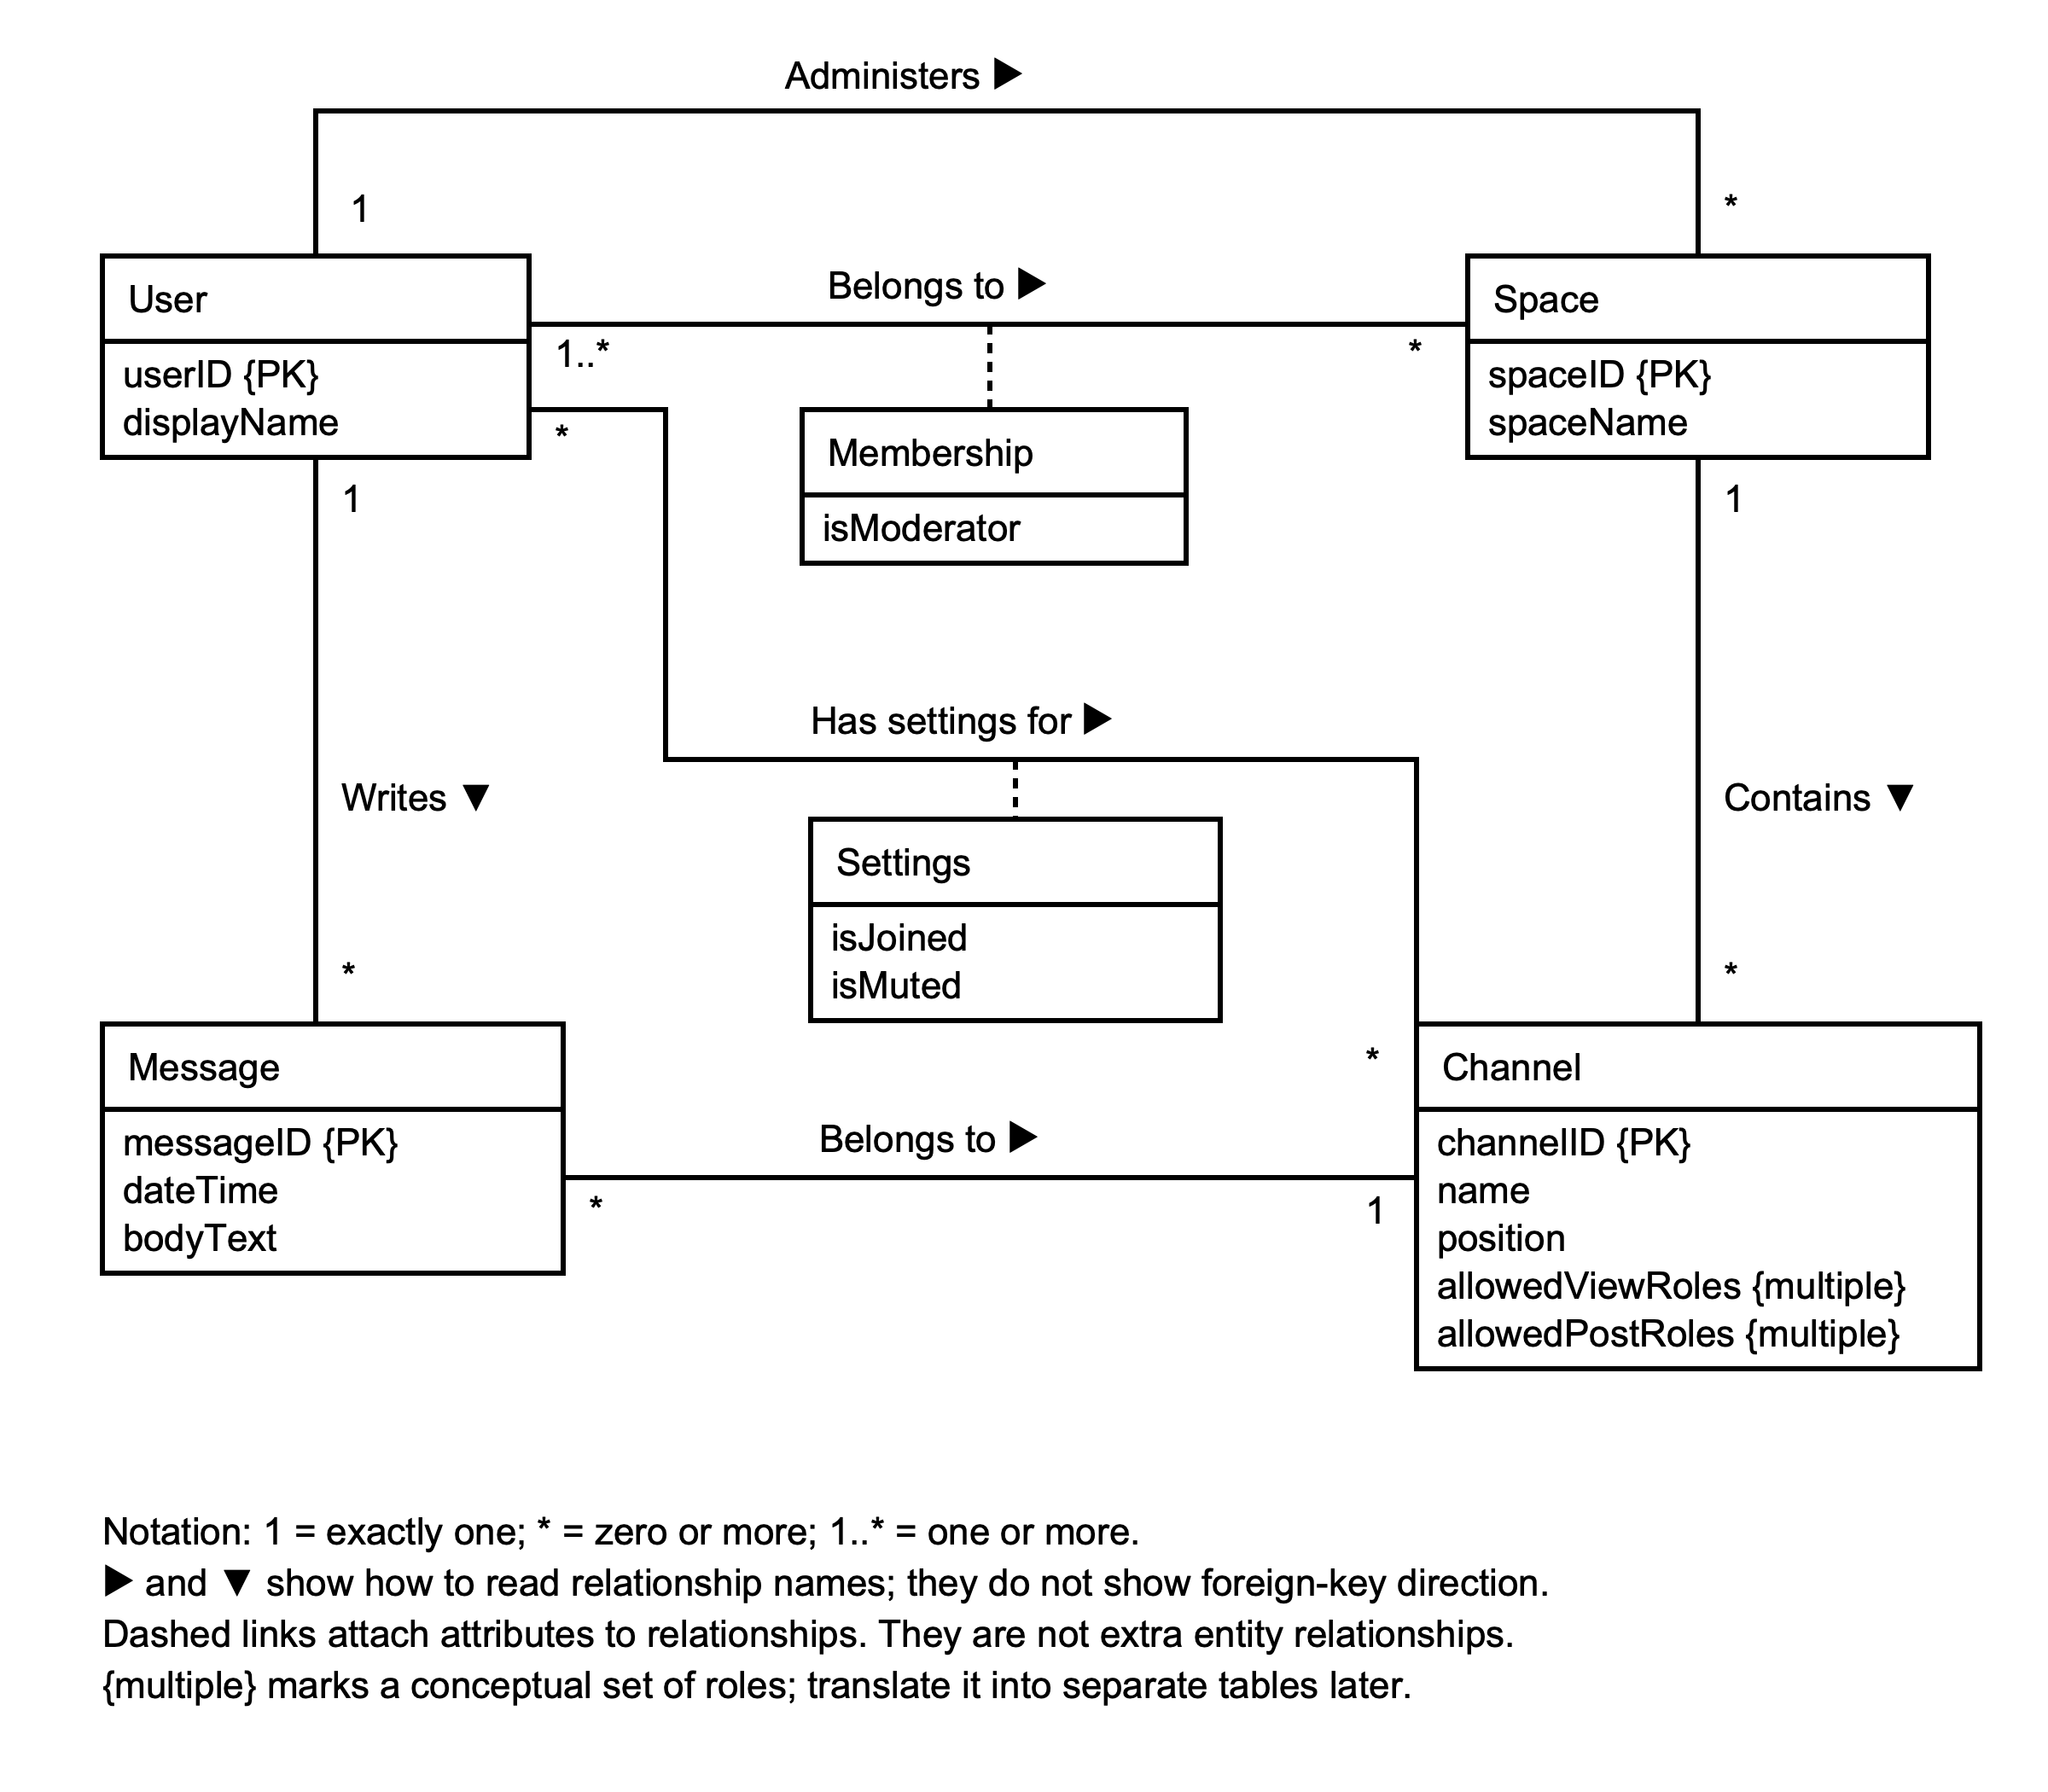

Plain rectangles contain entity names and attributes, as in your worksheet. `{PK}` identifies a primary key. Relationship names have reading-direction triangles, with multiplicities beside the entity ends.

The two dashed attribute boxes describe the User–Space membership and User–Channel settings relationships; they are not additional entity types. This diagram includes both relationship details, so they no longer need to be drawn separately.

Read numbers at the opposite end: one User can write `*` Messages; each Message is written by `1` User.


## 2. What the four boxes mean

| Box | Plain meaning | Attributes |
|---|---|---|
| User | A person with an account | userID, displayName |
| Space | A community, such as COMP0178 Students | spaceID, spaceName |
| Channel | A conversation area, such as General | channelID, name, position, allowedViewRoles, allowedPostRoles |
| Message | One posted message | messageID, dateTime, bodyText |

- IDs identify individual users, spaces, channels, and messages.
- `position` puts channels in order within their space: 1, 2, 3, and so on.
- Messages are ordered by `dateTime`, then `messageID` if two have the same time.
- `allowedViewRoles` and `allowedPostRoles` are sets of role names. Mark them **{multiple}** in this conceptual diagram. They are not comma-separated fields being proposed for a relational table.

## 3. Read the lines in plain English

| Line | Meaning |
|---|---|
| User belongs to Space | A user can join many spaces. A space has many users, including its admin. |
| User administers Space | Each space has exactly one admin/creator. A user may administer many spaces. |
| Space contains Channel | Each channel belongs to exactly one space. A space can have many channels. |
| User writes Message | Each message has exactly one creator. A user can write many messages. |
| Message belongs to Channel | Each message belongs to exactly one channel. A channel can contain many messages. |

**Numbers:** `1` means exactly one; `0..*` means zero or more; `1..*` means one or more. We assume a new space may have no channels yet, and a new channel may have no messages. A space has at least its admin as a member.

## 4. Add two relationship details to finish the answer

Some information describes a **pair of things**, rather than one box alone.

### A. Moderator status belongs to User–Space membership

Write `isModerator` beside the **belongs to** line between User and Space. It is an attribute of that relationship.

Example: Ada can be a moderator in Study Space and an ordinary member in Gaming Space. Therefore, moderator status should not be one global User attribute.

### B. Joined/muted settings belong to a User–Channel relationship

Add a **many-to-many line** from User to Channel, labelled **has settings for**, with `0..*` at both ends. Attach the attributes `isJoined` and `isMuted` to that line.

```text
User  0..* -------- has settings for -------- 0..*  Channel
                         |
                  isJoined, isMuted
```

This relationship is included in the main diagram; the small sketch above isolates it so you can read it easily.

| User | Channel | isJoined | isMuted |
|---|---|---|---|
| Ada | General | Yes | Yes |
| Ben | General | Yes | No |

Ada's mute affects **Ada only**. Ben can still receive notifications. Muting does not stop someone reading or posting.

In the lecture's UML-style notation, a relationship's attributes can be placed in a small attribute box connected to its line by a dashed line. These are relationship details, not global User or Channel attributes.

## 5. An easy way to show channel permissions

Use three role names: **Member, Moderator, Admin**. Each Channel has two conceptual attributes listing which roles may view and post.

| Channel | allowedViewRoles | allowedPostRoles |
|---|---|---|
| General | Member, Moderator, Admin | Member, Moderator, Admin |
| Mod announcements | Member, Moderator, Admin | Moderator, Admin |
| Moderator discussion | Moderator, Admin | Moderator, Admin |

This means ordinary members can **read announcements but cannot post them**, and cannot view moderator discussion.

A user's role is evaluated **within the channel's space**: the space's creator is Admin; a member marked `isModerator` is Moderator; other members are Member. Admins are included in all permission sets in this answer. Posting must also require viewing permission.

These fixed role sets provide a simpler conceptual solution than separate Role and Permission entity boxes. If arbitrary custom roles were required, the model would need extending.

## 6. Assumptions to write below your diagram

1. Each space's admin/creator is also a member of that space; admin and creator are treated as the same person.
2. A user has only one membership per space. The membership records whether they are a moderator there.
3. Only members of a channel's space may have settings for that channel or post messages there. They must also have permission to post.
4. Each user–channel pair has at most one settings relationship. No settings record means not joined and not muted.
5. Joining records a personal followed-channel choice; it does not override channel access permissions.
6. Display names are global user settings, not different names per space.
7. Channel positions are unique within a space. Message timestamps may tie, so messageID breaks ties.
8. Viewing and posting permissions use the fixed Member/Moderator/Admin roles. Multiple-valued role attributes are translated into separate relations later, not stored as SQL lists.

These assumptions fill gaps in the question; they are not extra facts explicitly supplied by it.

## 7. What to hand in for this question

- The four entity boxes and their attributes.
- The five relationships in the main diagram, with multiplicities.
- `isModerator` attached to the User–Space membership relationship.
- The extra User–Channel settings relationship, with `isJoined` and `isMuted`.
- Channel viewing/posting role attributes and a brief explanation of them.
- The assumptions needed to interpret your choices.

**Short explanation:** Users join Spaces and may be moderators within particular Spaces. Each Space has one admin and contains ordered Channels. Users create Messages in Channels. Joining and muting are personal User–Channel settings, while each Channel specifies which space roles may view or post.

This completes Conceptual Question 1. The worksheet's logical-design questions are separate.